# Упражнения по Boosting and Stacking

![Boosting.png](Assets/Boosting.png)

# Цели обучения

- Объяснить, как алгоритм бустинга помогает снизить дисперсию и систематическую ошибку.

## Введение

Мы будем использовать базу данных [«Распознавание действий человека с помощью смартфонов»](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), сформированную на основе записей участников исследования, выполнявших повседневные действия (ADL) с смартфоном, оснащенным встроенными инерционными датчиками. Цель состоит в классификации действий по одному из шести видов (ходьба, подъем по лестнице, спуск по лестнице, сидение, стояние и лежание).

Для каждой записи в наборе данных предоставляются следующие данные:

- Трехосное ускорение, полученное с акселерометра (общее ускорение), и расчетное ускорение тела.
- Трехосевая угловая скорость, полученная с гироскопа.
- Вектор из 561 признака с переменными во временной и частотной областях.
- Метка вида деятельности.

Более подробная информация о признаках доступна на указанном выше веб-сайте.

> **Пояснение**
> - **Бустинг** - это ансамбль (команда) простых моделей, которые обучаются **по очереди**: каждая следующая модель старается исправить ошибки предыдущих. В результате снижается и систематическая ошибка (смещение), и дисперсия.
> - Это отличие от баггинга прошлой недели, где деревья обучались независимо друг от друга и просто усреднялись.
> - **Gradient Boosting** добавляет деревья, которые «доучивают» остаточные ошибки. **AdaBoost** увеличивает вес тех объектов, на которых модель ошибается, чтобы следующие модели уделяли им больше внимания.
> - **Stacking / Voting** - объединение *разных* типов моделей (например, логистической регрессии и бустинга) в одну, которая берёт общее решение.

In [24]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import VotingClassifier

from sklearnex import patch_sklearn
patch_sklearn()

# Для графиков
import matplotlib.pyplot as plt
%matplotlib inline

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные из файла `Human_Activity_Recognition_Using_Smartphones_Data.csv` и проанализируйте структуру и типы данных. Типов данных будет слишком много, чтобы перечислять их по каждому столбцу отдельно. Вместо этого сгруппируйте типы по количеству.
* Определите, требуется ли масштабирование столбцов с числами типа float.

> - Читаем CSV в таблицу `data` и смотрим её размер (`shape` - число строк и столбцов).
> - Признаков 561, поэтому печатать тип каждого столбца бессмысленно. Метод `dtypes.value_counts()` просто считает, сколько столбцов каждого типа.
> - Масштабирование нужно, если признаки измеряются в сильно разных диапазонах (метры и тонны). Поэтому смотрим минимум и максимум по всем столбцам.
> - Обратите внимание: целевой столбец в файле называется **`Activity`** (в тексте ниже он назван «categories» - это одно и то же: столбец с названием действия).

In [25]:
import pandas as pd
import numpy as np

filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath, sep=',')

In [26]:
# Размер таблицы: (количество строк, количество столбцов)
print(data.shape)

# Первые 3 строки (первые столбцы)
data.iloc[:3, :5]

(10299, 562)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187


In [27]:
# Группируем столбцы по типам данных и считаем их количество
data.dtypes.value_counts()

float64    561
str          1
Name: count, dtype: int64

В наборе данных довольно много столбцов с предикторами.

In [28]:
# Какие столбцы НЕ имеют тип float64-
data.dtypes[data.dtypes != 'float64']

Activity    str
dtype: object

И все они - значения типа float. Единственное значение, не относящееся к типу float, - это столбец «categories», который и является объектом прогнозирования.

In [29]:
# Все столбцы типа float
float_columns = data.select_dtypes(include='float64').columns

# Минимум и максимум среди ВСЕХ значений float-столбцов
print('Минимум:', data[float_columns].min().min())
print('Максимум:', data[float_columns].max().max())

# Проверим, что у каждого столбца минимум и максимум одни и те же
print(data[float_columns].min().value_counts())
print(data[float_columns].max().value_counts())

Минимум: -1.0
Максимум: 1.0
-1.0    561
Name: count, dtype: int64
1.0    561
Name: count, dtype: int64


Минимальное и максимальное значения для столбцов типа float составляют -1,0 и 1,0 соответственно. Однако для методов, основанных на дереве, масштабирование никогда не требуется.

## Вопрос 2

* Присвойте действиям целочисленные коды.
* Разделите данные на обучающий и тестовый наборы. Решите, будет ли производиться стратификация данных при разделении на обучающий и тестовый наборы или нет.

> - Модели работают с числами, а действия записаны словами (`STANDING`, `WALKING`...). `LabelEncoder` присваивает каждому слову номер от 0 до 5 (по алфавиту).
> - Затем делим данные: на **обучающей** части модель учится, на **тестовой** мы проверяем качество.
> - `random_state=42` фиксирует случайность, чтобы результаты повторялись при каждом запуске.

**ПРИМЕЧАНИЕ**: Мы собираемся создать обучающий и тестовый наборы данных из `data`. На этих наборах данных мы будем проводить поиск по сетке с различными значениями параметров. Это может занять некоторое время. Чтобы сократить время поиска по сетке, вы можете уменьшить разрешение `data` и создать `X_train, X_test, y_train, y_test` на основе набора данных с уменьшенным разрешением.

Теперь разделите данные на обучающий и тестовый наборы. Здесь не использовалось стратифицированное деление. Если возникнут проблемы с какими-либо метриками ошибок на тестовом наборе, может быть целесообразно начать подбор модели с использованием стратифицированного деления. Однако метод бустинга является довольно мощной моделью, поэтому в данном случае это может оказаться ненужным.

In [30]:
# Превращаем названия действий в числа 0..5
le = LabelEncoder()
data['Activity'] = le.fit_transform(data['Activity'])

# Какой код соответствует какому действию
print({name: int(code) for code, name in enumerate(le.classes_)})

# Сколько строк каждого класса
data['Activity'].value_counts().sort_index()

{'LAYING': 0, 'SITTING': 1, 'STANDING': 2, 'WALKING': 3, 'WALKING_DOWNSTAIRS': 4, 'WALKING_UPSTAIRS': 5}


Activity
0    1944
1    1777
2    1906
3    1722
4    1406
5    1544
Name: count, dtype: int64

In [31]:
# Если поиск по сетке дальше идёт слишком долго, раскомментируйте строку ниже:
# она оставит только 30% случайных строк (так всё посчитается быстрее)
# data = data.sample(frac=0.3, random_state=42)

# X - признаки (все столбцы кроме Activity), y - ответ (Activity)
feature_cols = [c for c in data.columns if c != 'Activity']
X = data[feature_cols]
y = data['Activity']

# Обычное (не стратифицированное) деление: 70% обучение, 30% тест
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)

Обучающая выборка: (7209, 561)
Тестовая выборка: (3090, 561)


## Вопрос 3

* Постройте модели градиентного бустинга с деревьями, установив все параметры по умолчанию, для следующих значений количества деревьев (`n_estimators = [25, 50, 100, 200, 400]`) и оцените точность на тестовых данных для каждой из этих моделей.
* Постройте график зависимости точности от количества оценок.

**Примечание:** Выполнение этого задания может занять некоторое время в зависимости от количества различных значений, подбираемых для оценок. Установка параметра `max_features=4` в классификаторе градиентного бустинга увеличит скорость сходимости.

Кроме того, это задание аналогично заданию 3 из 9-й недели, за исключением того, что для моделей с бустингом не существует такого понятия, как «ошибка out-of-bag». Кроме того, в модели градиентного бустинга присутствует ошибка в настройке `warm_flag=True`, поэтому не используйте её. Просто создайте модель внутри цикла `for` и задайте количество оценок в этот момент. Это приведёт к тому, что подбор модели займёт немного больше времени. Кроме того, подбор моделей бустинга, как правило, занимает больше времени, чем подбор моделей методом bagging, поскольку «решающие пеньки» необходимо подбирать последовательно.

> **Пояснение.**
> В цикле `for` мы по очереди создаём модель градиентного бустинга с 25, 50, 100, 200 и 400 деревьями, обучаем её на обучающих данных и считаем **accuracy** (долю верных ответов) на тестовых. `max_features=4` означает, что при каждом разбиении дерево смотрит только на 4 случайных признака - так обучение идёт быстрее.

In [32]:
n_estimators_list = [25, 50, 100, 200, 400]
accuracy_list = []

for n in n_estimators_list:
    # Создаём модель с нужным числом деревьев
    model = GradientBoostingClassifier(n_estimators=n, max_features=4, random_state=42)
    model.fit(X_train, y_train)

    # Точность на тестовых данных
    acc = accuracy_score(y_test, model.predict(X_test))
    accuracy_list.append(acc)
    print('Деревьев:', n, ' точность:', round(acc, 4))

# Собираем результаты в таблицу
gbc_acc_df = pd.DataFrame({'n_estimators': n_estimators_list,
                           'accuracy': accuracy_list}).set_index('n_estimators')
gbc_acc_df

Деревьев: 25  точность: 0.9311
Деревьев: 50  точность: 0.9595
Деревьев: 100  точность: 0.9764
Деревьев: 200  точность: 0.9841
Деревьев: 400  точность: 0.9867


,accuracy
n_estimators,
25,0.931068
50,0.959547
100,0.976375
200,0.984142
400,0.986731


Теперь построим график результата.

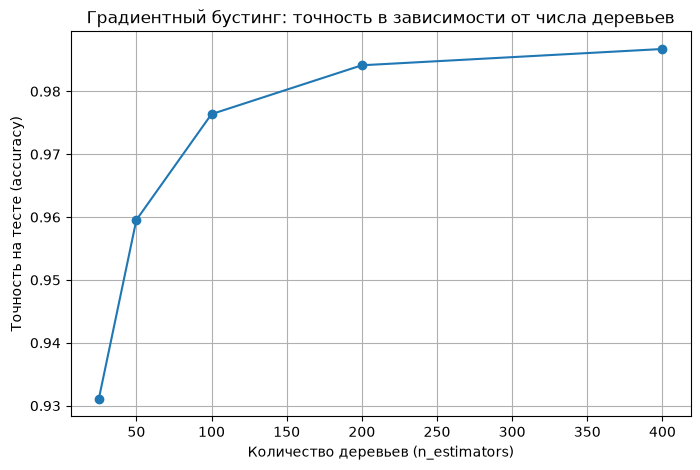

In [33]:
ax = gbc_acc_df.plot(marker='o', legend=False, figsize=(8, 5))
ax.set(xlabel='Количество деревьев (n_estimators)', ylabel='Точность на тесте (accuracy)',
       title='Градиентный бустинг: точность в зависимости от числа деревьев')
ax.grid()
plt.show()

## Вопрос 4

* Используя поиск по сетке с перекрестной валидацией, постройте новый классификатор с градиентным бустингом, используя список оценок, аналогично вопросу 3. Также рассмотрите возможность изменения скоростей обучения (0,1; 0,01; 0,001 и т. д.), значения подвыборки (1,0 или 0,5) и количества максимальных признаков (1, 2 и т. д.).
* Проанализируйте параметры модели с наилучшей подгонкой.
* Рассчитайте соответствующие метрики ошибок для этой модели и проанализируйте матрицу путаницы.

**Примечание:** выполнение этого вопроса может занять некоторое время в зависимости от количества признаков, используемых в поиске по сетке. Рекомендуется начать с небольшого количества, чтобы убедиться в корректной работе, а затем добавить больше признаков. Установка параметра `max_features=4` в классификаторе с градиентным бустингом увеличит скорость сходимости.

> - **Поиск по сетке (GridSearchCV)** перебирает все комбинации параметров из словаря `param_grid` и для каждой проверяет качество с помощью **кросс-валидации** (`cv=3`: обучающие данные делятся на 3 части, модель по очереди учится на двух и проверяется на третьей).
> - Параметры: `learning_rate` - «шаг обучения» (чем меньше, тем осторожнее, но нужно больше деревьев); `subsample` - какую долю строк использует каждое дерево; `max_features` - сколько признаков видит дерево при разбиении.
> - После поиска `best_params_` показывает лучшую комбинацию, а `best_estimator_` - уже обученную лучшую модель.
> - Для сетки взято немного значений, чтобы не ждать слишком долго. Если хотите, добавьте в списки ещё варианты (например, `n_estimators` 400 или `learning_rate` 0.001).

In [34]:
# Словарь параметров: ключ - название параметра, значение - список вариантов
param_grid_gbc = {
    'n_estimators': [100, 200],
    'learning_rate': [0.1, 0.01],
    'subsample': [1.0, 0.5],
    'max_features': [2, 4]
}

GV_GBC = GridSearchCV(GradientBoostingClassifier(random_state=42),
                      param_grid=param_grid_gbc,
                      scoring='accuracy',
                      cv=3,
                      n_jobs=-1)

GV_GBC.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.1, 0.01], 'max_features': [2, 4], 'n_estimators': [100, 200], 'subsample': [1.0, 0.5]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose:

In [35]:
# Лучшая комбинация параметров и её точность на кросс-валидации
print('Лучшие параметры:', GV_GBC.best_params_)
print('Точность на кросс-валидации:', round(GV_GBC.best_score_, 4))

# Лучшая (уже обученная) модель
GV_GBC.best_estimator_

Лучшие параметры: {'learning_rate': 0.1, 'max_features': 4, 'n_estimators': 200, 'subsample': 0.5}
Точность на кросс-валидации: 0.981


,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",0.5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_features max_features: {'sqrt', 'log2'}, int or float, default=NoneThe number of features to consider when looking for the best split:- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0]` and the features considered at each split will be `max(1, int(max_features * n_features_in_))`.- If 'sqrt', then `max_features=sqrt(n_features)`.- If 'log2', then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Choosing `max_features < n_features` leads to a reduction of varianceand an increase in bias.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",4
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Valu

In [36]:
# Предсказания лучшей модели на тестовых данных
y_pred_gbc = GV_GBC.best_estimator_.predict(X_test)

print('Accuracy на тесте:', round(accuracy_score(y_test, y_pred_gbc), 4))
print()
print(classification_report(y_test, y_pred_gbc))

Accuracy на тесте: 0.9816

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       597
           1       0.96      0.95      0.96       563
           2       0.96      0.96      0.96       547
           3       0.99      1.00      1.00       539
           4       1.00      0.99      0.99       420
           5       0.98      1.00      0.99       424

    accuracy                           0.98      3090
   macro avg       0.98      0.98      0.98      3090
weighted avg       0.98      0.98      0.98      3090



Показатели ошибок. Отчет о классификации особенно удобен в случаях с несколькими классами.

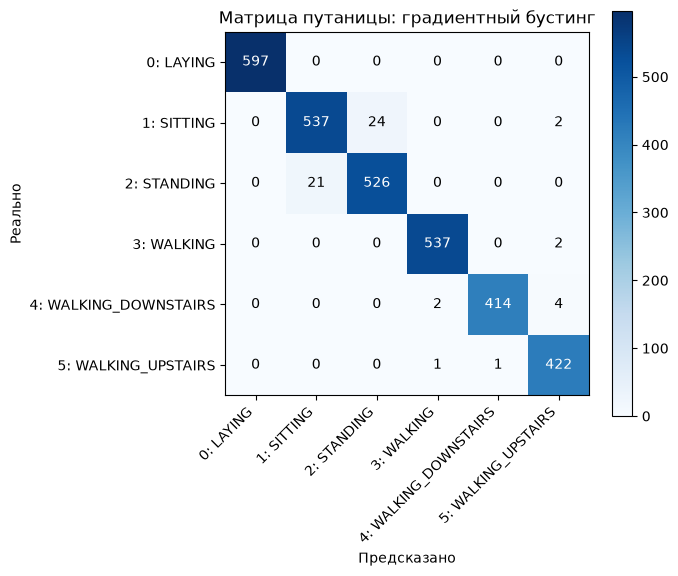

In [37]:
# Подписи классов: код и название действия
class_labels = [str(i) + ': ' + name for i, name in enumerate(le.classes_)]

# Вспомогательная функция 1: рисует матрицу путаницы
# (normalize=True - показывает доли внутри каждой строки вместо количества объектов)
def plot_cm(cm, title, normalize=False):
    cm_show = cm / cm.sum(axis=1, keepdims=True) if normalize else cm
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm_show, cmap='Blues')
    ax.set_xticks(range(len(class_labels)))
    ax.set_yticks(range(len(class_labels)))
    ax.set_xticklabels(class_labels, rotation=45, ha='right')
    ax.set_yticklabels(class_labels)
    ax.set_xlabel('Предсказано')
    ax.set_ylabel('Реально')
    ax.set_title(title)
    # Числа внутри клеток
    for i in range(cm_show.shape[0]):
        for j in range(cm_show.shape[1]):
            text = '{:.2f}'.format(cm_show[i, j]) if normalize else cm_show[i, j]
            ax.text(j, i, text, ha='center', va='center',
                    color='white' if cm_show[i, j] > cm_show.max() / 2 else 'black')
    plt.colorbar(im)
    plt.tight_layout()
    plt.show()

# Вспомогательная функция 2: матрица путаницы в виде таблицы с подписями
def cm_table(cm):
    return pd.DataFrame(cm, index=class_labels, columns=class_labels)

cm_gbc = confusion_matrix(y_test, y_pred_gbc)
plot_cm(cm_gbc, 'Матрица путаницы: градиентный бустинг')

Матрица путаницы. Обратите внимание, что модель с градиентным бустингом испытывает небольшие затруднения при различении классов активности 1 и 2.

## Вопрос 5

* Создайте модель AdaBoost и подстройте её с помощью поиска по сетке, аналогично вопросу 4. Попробуйте использовать различные значения оценщика в диапазоне от 100 до 200.
* Сравните погрешности модели AdaBoost с погрешностями модели GradientBoostedClassifier.

**ПРИМЕЧАНИЕ:** Установка параметра `max_features=4` в классификаторе на основе дерева решений, используемом в качестве базового классификатора для AdaBoost, повысит скорость сходимости.

> AdaBoost по умолчанию строит последовательность очень простых деревьев - **«пеньков»** (`max_depth=1`, то есть одно разбиение). После каждого дерева он увеличивает вес объектов, которые были классифицированы неверно. Базовое дерево (`DecisionTreeClassifier`) мы передаём первым аргументом, а в сетке перебираем число деревьев (от 100 до 200) и `learning_rate`.

In [38]:
# Базовая модель - "пенёк" (дерево глубины 1), видящий 4 случайных признака
base_tree = DecisionTreeClassifier(max_depth=1, max_features=4, random_state=42)

ABC = AdaBoostClassifier(base_tree, random_state=42)

param_grid_ada = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [1.0, 0.5, 0.1]
}

GV_ABC = GridSearchCV(ABC,
                      param_grid=param_grid_ada,
                      scoring='accuracy',
                      cv=3,
                      n_jobs=-1)

GV_ABC.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",AdaBoostClass...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [1.0, 0.5, ...], 'n_estimators': [100, 150, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of

Лучшая модель.

In [39]:
print('Лучшие параметры:', GV_ABC.best_params_)
print('Точность на кросс-валидации:', round(GV_ABC.best_score_, 4))

GV_ABC.best_estimator_

Лучшие параметры: {'learning_rate': 1.0, 'n_estimators': 200}
Точность на кросс-валидации: 0.5701


,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ndom_state=42)
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](6,)","[0,1,2,3,4,5]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...ndom_state=42)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](200,)","[0.65,0.57,0.43,...,0.53,0.55,0.52]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](200,)","[1. ,1.33,1.91,...,1.51,1.43,1.53]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](561,)","[0.,0.,0.,...,0.,0.,0.]"


Accuracy на тесте: 0.6265

              precision    recall  f1-score   support

           0       0.97      0.86      0.91       597
           1       0.61      0.24      0.34       563
           2       0.53      0.93      0.67       547
           3       0.67      0.65      0.66       539
           4       0.81      0.25      0.38       420
           5       0.45      0.77      0.57       424

    accuracy                           0.63      3090
   macro avg       0.67      0.62      0.59      3090
weighted avg       0.68      0.63      0.60      3090



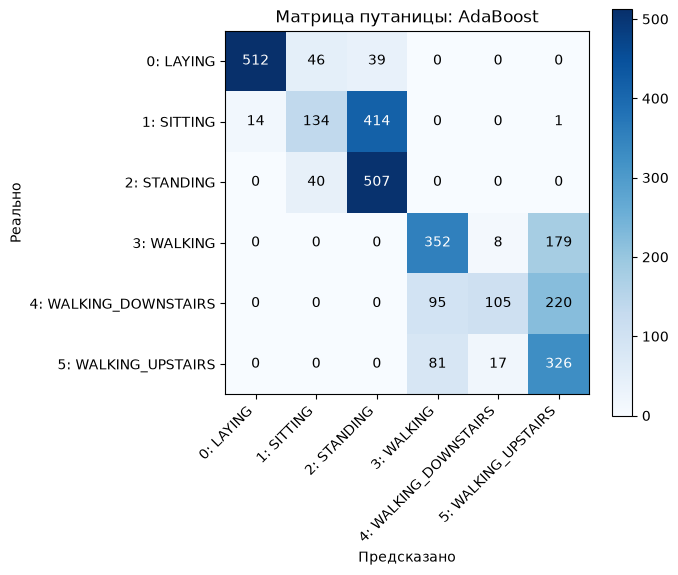

In [40]:
# Предсказания AdaBoost на тестовых данных
y_pred_ada = GV_ABC.best_estimator_.predict(X_test)

print('Accuracy на тесте:', round(accuracy_score(y_test, y_pred_ada), 4))
print()
print(classification_report(y_test, y_pred_ada))

cm_ada = confusion_matrix(y_test, y_pred_ada)
plot_cm(cm_ada, 'Матрица путаницы: AdaBoost')

Показатели ошибок. Обратите внимание, что проблемы с классами 1 и 2, по-видимому, усугубились и теперь затрагивают также класс 0. Также обратите внимание на другие проблемы, связанные с классами 3-5. Алгоритм AdaBoost очень чувствителен к выбросам, поэтому именно в этом может заключаться причина проблемы.

In [41]:
# Сравнение двух моделей по точности на тесте
compare_df = pd.DataFrame({
    'Модель': ['Gradient Boosting', 'AdaBoost'],
    'Accuracy на тесте': [accuracy_score(y_test, y_pred_gbc), accuracy_score(y_test, y_pred_ada)]
}).set_index('Модель').round(4)

compare_df

,Accuracy на тесте
Модель,
Gradient Boosting,0.9816
AdaBoost,0.6265


## Вопрос 6

* Постройте модель логистической регрессии с регуляризацией. Это может быть аналог модели, которая хорошо себя показала в упражнениях 4-й недели.
* Используя `VotingClassifier`, постройте модель логистической регрессии вместе с моделью GratientBoostedClassifier или AdaBoost (или обеими) из вопросов 4 и 5.
* Определите ошибку, как и ранее, и сравните результаты с соответствующими моделями с градиентным бустингом.
* Постройте матрицу путаницы для лучшей модели, созданной в этом наборе упражнений.

> - **Логистическая регрессия** - простая линейная модель для классификации. **Регуляризация** (по умолчанию L2) штрафует слишком большие коэффициенты и защищает от переобучения. `LogisticRegressionCV` сама подбирает силу регуляризации (параметр `Cs`) с помощью кросс-валидации.
> - **VotingClassifier** объединяет несколько разных моделей. При `voting='soft'` каждая модель выдаёт вероятности классов, вероятности усредняются, и выбирается класс с наибольшей средней вероятностью.
> - В конце сравним точность всех моделей и нарисуем матрицу путаницы для лучшей.

In [42]:
# Логистическая регрессия с L2-регуляризацией; коэффициент регуляризации выбирается кросс-валидацией
LR_L2 = LogisticRegressionCV(Cs=10, cv=3, max_iter=500, n_jobs=-1,
                          l1_ratios=(0,), scoring='accuracy', use_legacy_attributes=True)
LR_L2.fit(X_train, y_train)

y_pred_lr = LR_L2.predict(X_test)
print('Accuracy на тесте:', round(accuracy_score(y_test, y_pred_lr), 4))

Accuracy на тесте: 0.9825


Проверьте ошибки и матрицу путаницы для модели логистической регрессии.

In [43]:
print(classification_report(y_test, y_pred_lr))

# Матрица путаницы в виде таблицы (строки - реальные классы, столбцы - предсказанные)
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_table(cm_lr)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       597
           1       0.96      0.95      0.96       563
           2       0.96      0.96      0.96       547
           3       1.00      1.00      1.00       539
           4       1.00      1.00      1.00       420
           5       0.99      1.00      0.99       424

    accuracy                           0.98      3090
   macro avg       0.98      0.98      0.98      3090
weighted avg       0.98      0.98      0.98      3090



,0: LAYING,1: SITTING,2: STANDING,3: WALKING,4: WALKING_DOWNSTAIRS,5: WALKING_UPSTAIRS
0: LAYING,597,0,0,0,0,0
1: SITTING,1,534,24,0,0,4
2: STANDING,0,21,525,1,0,0
3: WALKING,0,0,0,537,1,1
4: WALKING_DOWNSTAIRS,0,0,0,0,419,1
5: WALKING_UPSTAIRS,0,0,0,0,0,424


А теперь - многоуровневая модель (stacked model).

In [44]:
# Объединяем три модели: логистическую регрессию и лучшие модели из вопросов 4 и 5
estimators = [('lr', LR_L2),
              ('gbc', GV_GBC.best_estimator_),
              ('ada', GV_ABC.best_estimator_)]

# voting='soft' - усредняем вероятности классов
VC = VotingClassifier(estimators=estimators, voting='soft')
VC.fit(X_train, y_train)

y_pred_vc = VC.predict(X_test)
print('Accuracy на тесте:', round(accuracy_score(y_test, y_pred_vc), 4))

Accuracy на тесте: 0.9845


In [45]:
# Матрицу путаницы для этой модели не рисуем здесь: если она лучшая, она будет в самой последней ячейке
print(classification_report(y_test, y_pred_vc))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       597
           1       0.97      0.95      0.96       563
           2       0.96      0.96      0.96       547
           3       1.00      1.00      1.00       539
           4       1.00      1.00      1.00       420
           5       0.99      1.00      0.99       424

    accuracy                           0.98      3090
   macro avg       0.99      0.99      0.99      3090
weighted avg       0.98      0.98      0.98      3090



Наконец, рассмотрим ошибку классификатора при голосовании. Здесь мы показываем немного лучшие результаты, чем при использовании либо логистической регрессии, либо градиентных бустеров по отдельности. Однако тот факт, что логистическая регрессия демонстрирует почти такие же результаты, как и градиентные бустеры, служит важным напоминанием о том, что сначала следует пробовать самую простую модель. В некоторых случаях её эффективности будет вполне достаточно.

                         Accuracy на тесте
Gradient Boosting                   0.9816
AdaBoost                            0.6265
Logistic Regression                 0.9825
Voting (LR + GBC + Ada)             0.9845

Лучшая модель: Voting (LR + GBC + Ada)


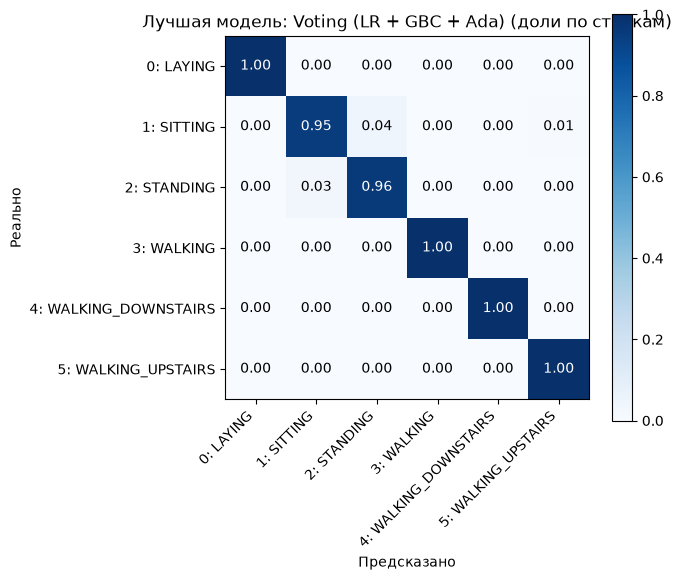

In [46]:
# Итоговое сравнение всех моделей
predictions = {
    'Gradient Boosting': y_pred_gbc,
    'AdaBoost': y_pred_ada,
    'Logistic Regression': y_pred_lr,
    'Voting (LR + GBC + Ada)': y_pred_vc
}

final_df = pd.DataFrame({'Accuracy на тесте': {name: accuracy_score(y_test, pred)
                                                for name, pred in predictions.items()}}).round(4)
print(final_df)

# Лучшая модель по точности на тесте и её матрица путаницы
best_name = final_df['Accuracy на тесте'].idxmax()
print()
print('Лучшая модель:', best_name)
# Для лучшей модели рисуем матрицу в долях: какая часть каждого реального класса распознана верно
plot_cm(confusion_matrix(y_test, predictions[best_name]),
        'Лучшая модель: ' + best_name + ' (доли по строкам)', normalize=True)